Simulating hodgkin huxley neurons in C++
This is just a quick bit of testing, but may provide a base for an improved version of the simulator

Basic features:
Single compartment conductance based neurons
Voltage and ligand gating 
Simple conductance based synapses

Conductance based neurons:
Resting membrane potential defined in terms of membrane conductances for each ion # Nernst potentials for Na, K, Cl, and Ca, and 
Monoexponential gating defined in terms of Vhalf, Vk, theta0 theta1 sig0 k0

The fundamental principle guiding the simulation code is that we avoid any conditional (if) statements. This means we end up doing a lot of unnecessary calculations, but it allows us to run the code on a GPU which more thank makes up for it. 
I dont like the idea of current injection, or even of bias currents. I think its unphysiological to have a constant current that does not changed based on neural or external conditions.  

Extra features:
Multicompartments
ChatGPT compile python to c++
Delays
Gap junctions 
Short term plasticity
Long term calcium based plasticity 

In [1]:
from auxillaryFunctions import *
# build_dir,configType = "build", "Debug"
# moduleDir = os.path.join(build_dir, configType)
# if moduleDir not in sys.path:
#     sys.path.append(moduleDir)

# import cathalTest
np.random.seed(0)
#neurons
#NOTE: This latest update began as me wanting to add the ability to simulate neurons and add spikers, but has changed into me trying to better initialize sims
STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
STNbias = -2.25
GPeBias = -.23 #-0.23

TS = 0.05  
nSTN,nGPe,nIdk = 1,1,0
nCTX,nMSN = 1,1
CTXrate,MSNrate = 3.3,2.1
k = 1
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe


STNDendriteMap = []
STNDendriteInfo = []

#STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias) for i in range(nSTN)]
GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nGPe)]

CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]

neuronDict = {"GPe":GPeNeurons}#,"GPe":GPeNeurons,"idk":idkNeurons}
spikerDict = {"MSN":MSNSpikers} #{"CTX":CTXSpikers}#,

#CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,0.015,0.2,TS)
MSNToGPeSynapses = createSynapses(MSNSpikers,GPeNeurons,nGPe_GPe,0.2,0.2,TS)
synapseDict =  {"MSNToGPe":MSNToGPeSynapses} #{"CTXToSTN":CTXToSTNSynapses }

simData,connectionToChannelMap = genSimData(neuronDict,spikerDict,synapseDict,TS)
#NOTE: 25 July 25: the STN-GPE system seems to work (no bugs or crashing), but behaviour is not as expected. Not sure why, maybe diffusion connections
#NOTE: 28 July 25: Next step is to get this working nicely on the c++ end, then try CUDA
#first I want to change how currents are accumulated so that this can be more easily parallelized
#stop using netCurrent and start using "current" with an index that matches channels to neurons
#chanToNeuron[chanId] = neuronId
#for nId,current in zip(chanToNeuron,currents): netCurrent[nId] += current
#This is basically done 28/7, just need to port to c++

#On the c++ end, we need to update a few things:
#New spiker - neuron separation
#spike and bias overwrite 




c:\Users\catha\source\repos\pythonCPPtesting.ipynb\auxillaryFunctions.py:48: RuntimeWarning: overflow encountered in exp
  return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))


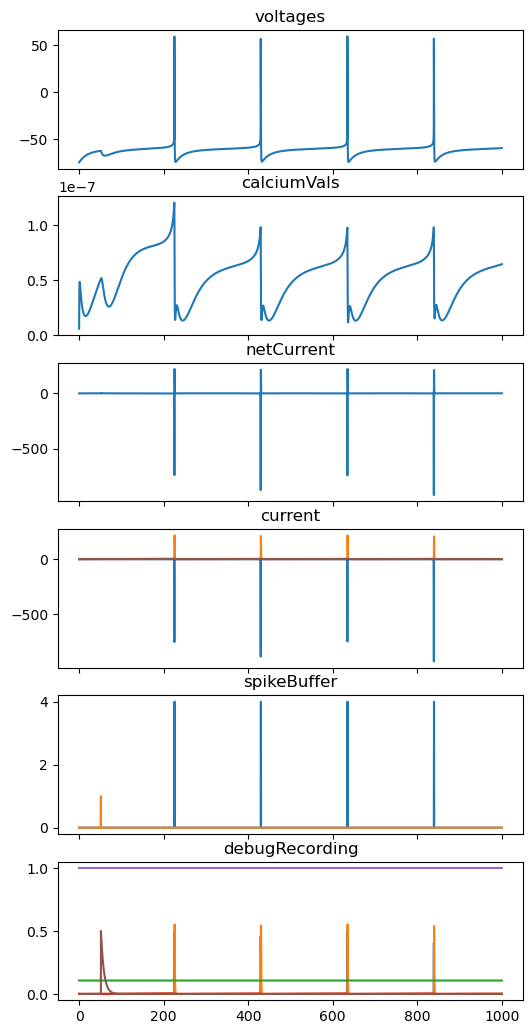

In [2]:

synapsesToStim = [] #[connectionToChannelMap["STNtoGPe"][1]]
runTime = 1000
biasNeuron,biasVal = 0,-10
st0,st1=10,11
st0,st1 = int(st0/TS),int(st1/TS)
stimInfoCurrents = {} #{i:{biasNeuron:biasVal} for i in range(st0,st1)}
# channel inputs are overwritten at a particular iteration, on a per channel basis (as opposed to overwritting a axon)
stimInfoSpikes = {} #{i:synapsesToStim for i in range(st0,st1)}
simDataPy = deepcopy(simData)
simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])
data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,recordingKeys = ["voltages","calciumVals","netCurrent","current","spikeBuffer","debugRecording"])
standardPlot(data)
#plt.plot(data["time"],data["debugRecording"][:,synapsesToStim])

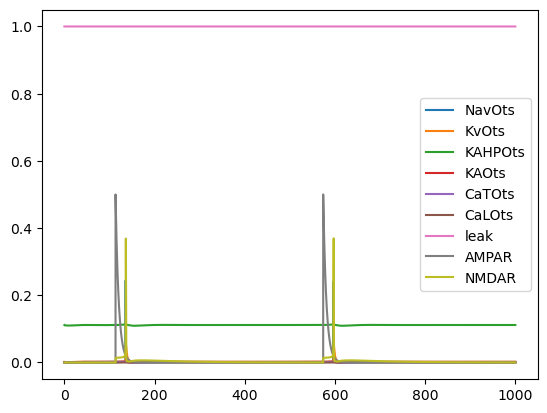

In [15]:
plt.plot(data["time"],data["debugRecording"][:,:],label=simData["name"])
plt.legend()

In [45]:
connectionToChannelMap["CTXtoSTN"][1]

126

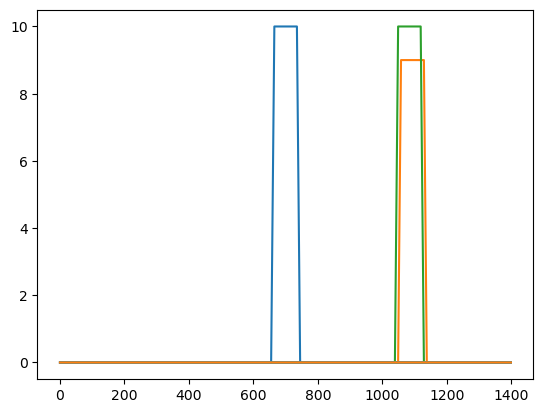

In [4]:
x = data["spikeBuffer"].sum(axis=2)
plt.plot(x);

[[False False  True ... False False False]
 [False False  True ... False False False]
 [False False  True ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


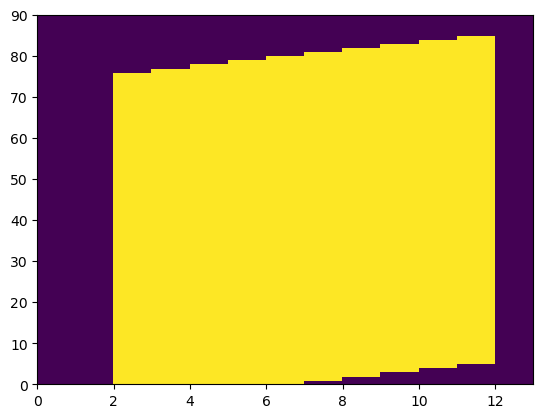

In [5]:
y = data["spikeBuffer"][660:750,0,14:27]
plt.pcolor(y)
print(y)